In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
#import libraries

In [2]:
df_customer = pd.read_csv("../data/raw/customer_master.csv")  #import customer data

In [3]:
df_customer.head()

,Customer_ID,Region,Province,Segment,Account_Manager
0,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc
1,CUST00002,Western Canada,Manitoba,Mid-Market,Sophie Martin
2,CUST00003,Northern Canada,Nunavut,Small Business,Jennifer Singh
3,CUST00004,Northern Canada,Yukon,Startup,Daniel Leblanc
4,CUST00005,Atlantic Canada,Nova Scotia,Enterprise,Aisha Mohammed


In [4]:
df_trans = pd.read_csv("../data/raw/customer_transactions.csv", 
                       parse_dates=["Transaction_Date"])  #import transaction data

In [5]:
df_trans.head()

,Transaction_ID,Customer_ID,Transaction_Date,Product_Category,Quantity,Unit_Price,Total_Amount
0,TXN000575,CUST00065,2025-02-15,Support,29,3763.82,109150.78
1,TXN000439,CUST00001,2025-02-15,Consulting,29,3312.27,96055.83
2,TXN000259,CUST00097,2025-02-15,Support,10,1127.45,11274.50
3,TXN000088,CUST00017,2025-02-15,Support,34,2714.74,92301.16
4,TXN000166,CUST00084,2025-02-15,Consulting,24,848.75,20370.00


In [6]:
df_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Customer_ID      200 non-null    str  
 1   Region           200 non-null    str  
 2   Province         200 non-null    str  
 3   Segment          200 non-null    str  
 4   Account_Manager  200 non-null    str  
dtypes: str(5)
memory usage: 7.9 KB


In [7]:
df_trans.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    1000 non-null   str           
 1   Customer_ID       1000 non-null   str           
 2   Transaction_Date  1000 non-null   datetime64[us]
 3   Product_Category  1000 non-null   str           
 4   Quantity          1000 non-null   int64         
 5   Unit_Price        1000 non-null   float64       
 6   Total_Amount      1000 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(3)
memory usage: 54.8 KB


**Imported both the Customer dataset and Transaction dataset. Now to combine them on the Customer ID**

In [8]:
df=pd.merge(df_customer, df_trans,
         how = 'inner', on='Customer_ID')

In [9]:
df.head()

,Customer_ID,Region,Province,Segment,Account_Manager,Transaction_ID,Transaction_Date,Product_Category,Quantity,Unit_Price,Total_Amount
0,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc,TXN000439,2025-02-15,Consulting,29,3312.27,96055.83
1,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc,TXN000172,2025-03-20,Support,19,1803.64,34269.16
2,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc,TXN000471,2025-06-19,Software,43,4866.73,209269.39
3,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc,TXN000532,2025-07-12,Services,28,3824.11,107075.08
4,CUST00001,Atlantic Canada,New Brunswick,Mid-Market,Daniel Leblanc,TXN000444,2026-01-29,Software,38,3700.26,140609.88


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Customer_ID       1000 non-null   str           
 1   Region            1000 non-null   str           
 2   Province          1000 non-null   str           
 3   Segment           1000 non-null   str           
 4   Account_Manager   1000 non-null   str           
 5   Transaction_ID    1000 non-null   str           
 6   Transaction_Date  1000 non-null   datetime64[us]
 7   Product_Category  1000 non-null   str           
 8   Quantity          1000 non-null   int64         
 9   Unit_Price        1000 non-null   float64       
 10  Total_Amount      1000 non-null   float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(7)
memory usage: 86.1 KB


## Data Quality

Before exploring the data, check that it can be trusted: missing values, duplicate transactions, whether the totals add up, customers that dropped out of the merge, and gaps in the dates.

In [11]:
print(df_customer.isna().sum(), '\n')
print(df_trans.isna().sum())  #count missing values in each column

Customer_ID        0
Region             0
Province           0
Segment            0
Account_Manager    0
dtype: int64 

Transaction_ID      0
Customer_ID         0
Transaction_Date    0
Product_Category    0
Quantity            0
Unit_Price          0
Total_Amount        0
dtype: int64


**Missing values:** None. Every column in both files is fully filled in, so nothing needs to be dropped or filled.

In [12]:
print('Repeated Transaction_IDs:', df_trans['Transaction_ID'].duplicated().sum())
print('Fully repeated rows:', df_trans.duplicated().sum())  #check for double-counted transactions

Repeated Transaction_IDs: 0
Fully repeated rows: 0


**Duplicate transactions:** None. Each of the 1,000 transactions has its own ID and no row appears twice, so no sales are being counted more than once.

In [13]:
amount_diff = (df_trans['Total_Amount'] - df_trans['Quantity'] * df_trans['Unit_Price']).abs()
mismatches = df_trans[amount_diff > 0.01]  #allow for rounding to the cent
print('Largest difference:', round(amount_diff.max(), 2))
print('Rows where Total_Amount does not match:', len(mismatches))

Largest difference: 0.0
Rows where Total_Amount does not match: 0


**Do the totals add up?** Yes. On every row, `Total_Amount` equals `Quantity × Unit_Price` to the cent, so `Total_Amount` can be used for sales without recalculating it.

In [14]:
unknown_customers = df_trans[~df_trans['Customer_ID'].isin(df_customer['Customer_ID'])]
print('Transactions with a Customer_ID not in the customer file:', len(unknown_customers))
df_customer[~df_customer['Customer_ID'].isin(df_trans['Customer_ID'])]  #customers dropped by the inner join

Transactions with a Customer_ID not in the customer file: 0


,Customer_ID,Region,Province,Segment,Account_Manager
111,CUST00112,Atlantic Canada,Prince Edward Island,Small Business,Jennifer Singh


**Customers with no transactions:** One customer, `CUST00112` (Atlantic Canada, Small Business), never bought anything, so the inner join leaves them out and the merged data has 199 customers instead of 200. This doesn't affect sales totals. In the other direction, every transaction belongs to a known customer, so the merge didn't lose any sales.

In [15]:
first_date = df['Transaction_Date'].min()
last_date = df['Transaction_Date'].max()
all_dates = pd.date_range(first_date, last_date, freq='D')
missing_dates = all_dates.difference(df['Transaction_Date'].unique())  #calendar days with no transactions
print('Date range:', first_date.date(), 'to', last_date.date())
print('Calendar days:', len(all_dates), '| Days with sales:', df['Transaction_Date'].nunique(),
      '| Days with no sales:', len(missing_dates))
print(missing_dates.strftime('%Y-%m-%d').tolist())

Date range: 2025-02-15 to 2026-02-14
Calendar days: 365 | Days with sales: 335 | Days with no sales: 30
['2025-03-07', '2025-03-10', '2025-03-19', '2025-03-23', '2025-03-31', '2025-04-05', '2025-04-26', '2025-05-02', '2025-05-04', '2025-05-25', '2025-06-10', '2025-06-18', '2025-06-29', '2025-08-02', '2025-09-06', '2025-09-08', '2025-09-10', '2025-10-20', '2025-10-30', '2025-11-12', '2025-11-17', '2025-11-20', '2025-11-25', '2025-12-01', '2025-12-09', '2025-12-15', '2025-12-25', '2026-01-05', '2026-01-23', '2026-01-25']


In [16]:
pd.Series(missing_dates.day_name()).value_counts()  #which weekdays have no sales

Monday       8
Sunday       5
Wednesday    4
Saturday     4
Friday       3
Tuesday      3
Thursday     3
Name: count, dtype: int64

**Date range and missing days:** The data covers exactly one year, from 15 Feb 2025 to 14 Feb 2026 (365 days), but only 335 days have any transactions. The other 30 days are spread across every month and every weekday (Mondays a little more often, 8 of the 30), with no long gaps. They look like quiet days with no sales rather than missing records, though the data can't confirm that.

This matters for the time-series steps below. Grouping by `Transaction_Date` only creates rows for days that had sales, so the 30 empty days are skipped instead of showing as zero. Left that way, the 7-row rolling average and the weekly (`period=7`) STL decomposition would actually cover a bit more than a week each time, which can blur weekly patterns. To avoid this, the daily series below are filled out to every calendar day, with 0 for days with no sales.

In [17]:
#pip install dtale  #install dtale for EDA

In [18]:
import dtale
#dtale.show(df)

<Axes: ylabel='Quantity'>

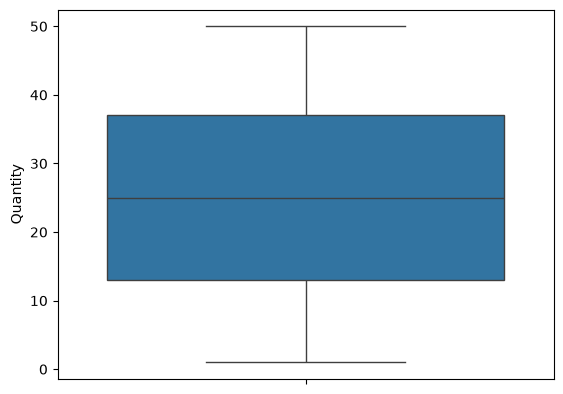

In [19]:
sns.boxplot(y='Quantity', data=df)

<Axes: ylabel='Unit_Price'>

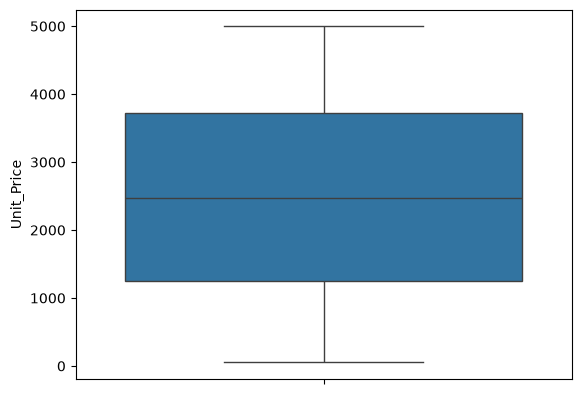

In [20]:
sns.boxplot(y='Unit_Price', data=df)

<Axes: ylabel='Total_Amount'>

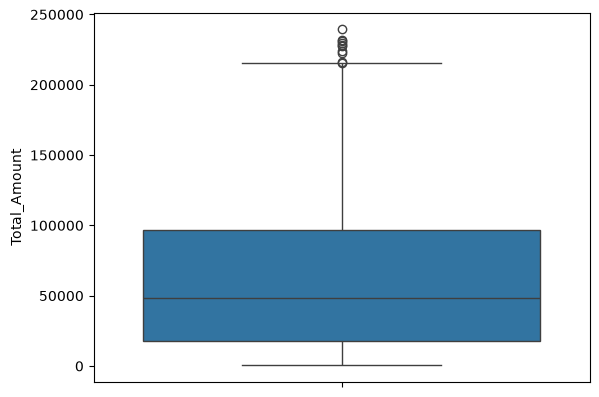

In [21]:
sns.boxplot(y='Total_Amount', data=df)

In [22]:
df[['Quantity', 'Unit_Price', 'Total_Amount']].describe()

,Quantity,Unit_Price,Total_Amount
count,1000.000000,1000.000000,1000.000000
mean,25.454000,2490.787530,64140.046350
std,14.311768,1422.518923,55234.368523
min,1.000000,53.230000,489.480000
25%,13.000000,1245.425000,17938.702500
50%,25.000000,2466.415000,48337.375000
75%,37.000000,3721.885000,96866.880000
max,50.000000,4997.810000,239422.820000


In [23]:
df.describe(include=['object', 'str'])

,Customer_ID,Region,Province,Segment,Account_Manager,Transaction_ID,Product_Category
count,1000,1000,1000,1000,1000,1000,1000
unique,199,4,13,4,16,1000,6
top,CUST00012,Atlantic Canada,Northwest Territories,Small Business,David Kim,TXN000439,Consulting
freq,11,329,130,384,88,1,186


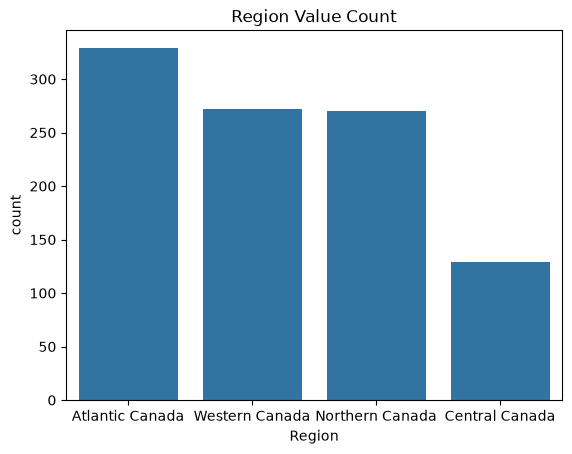

In [24]:
sns.countplot(x='Region', data=df)
plt.title('Region Value Count')
plt.show()

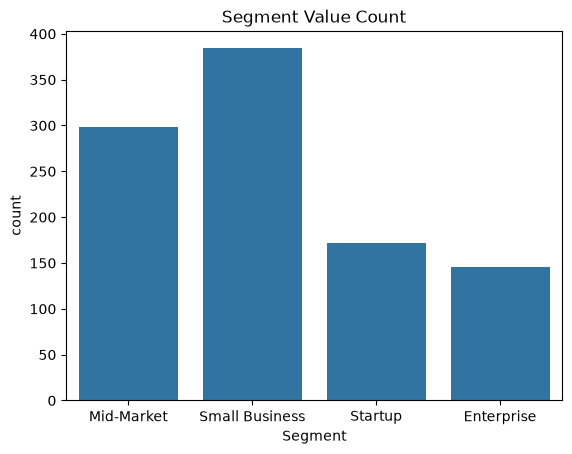

In [25]:
sns.countplot(x='Segment', data=df)
plt.title('Segment Value Count')
plt.show()

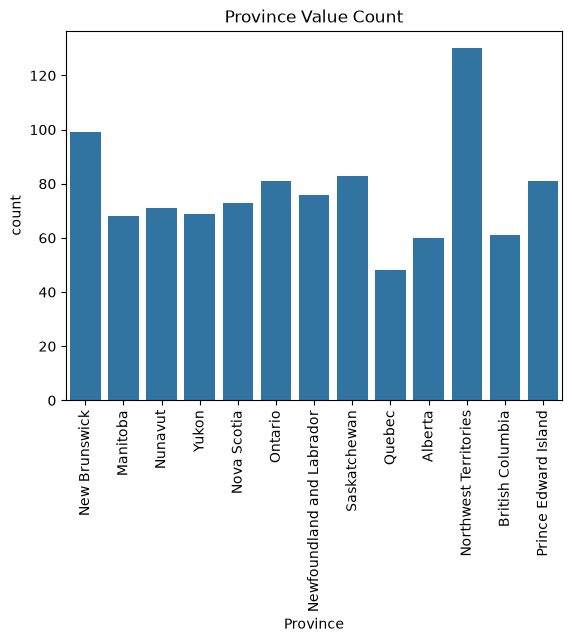

In [26]:
sns.countplot(x='Province', data=df)
plt.title('Province Value Count')
plt.xticks(rotation=90)
plt.show()

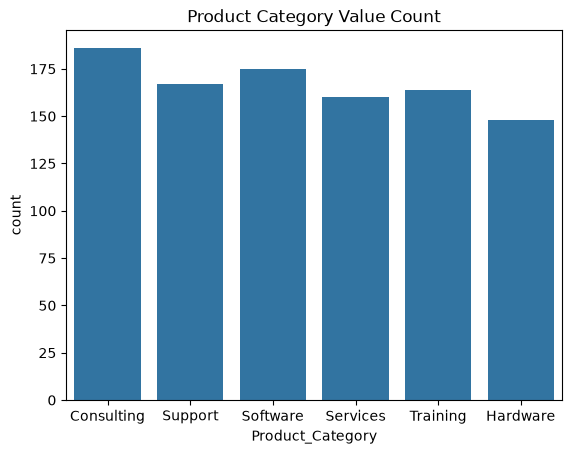

In [27]:
sns.countplot(x='Product_Category', data=df)
plt.title('Product Category Value Count')
plt.show()

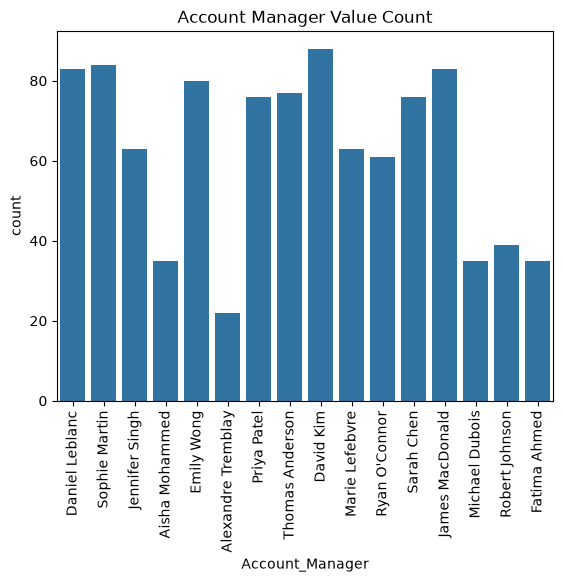

In [28]:
sns.countplot(x='Account_Manager', data=df)
plt.title('Account Manager Value Count')
plt.xticks(rotation=90)
plt.show()

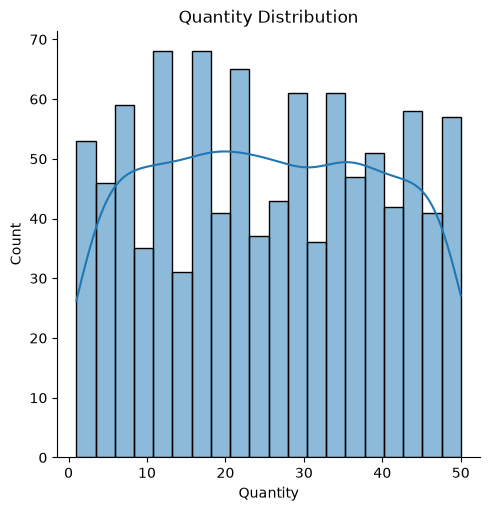

In [29]:
sns.displot(df['Quantity'], bins=20, kde='True')
plt.title('Quantity Distribution')
plt.show()

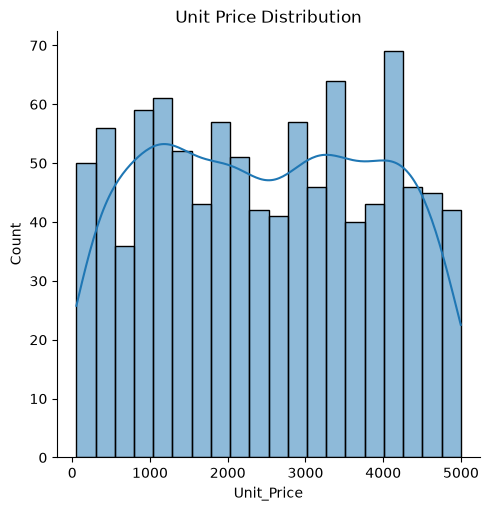

In [30]:
sns.displot(df['Unit_Price'], bins=20, kde='True')
plt.title('Unit Price Distribution')
plt.show()

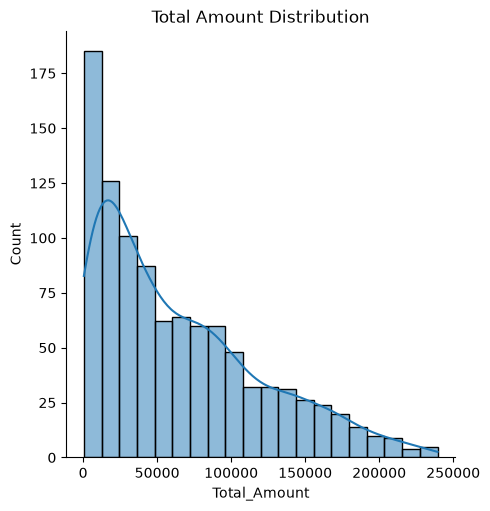

In [31]:
sns.displot(df['Total_Amount'], bins=20, kde='True')
plt.title('Total Amount Distribution')
plt.show()

**Splitting the dataset for forecasting, one data set for volumes and another for total sales.**

Each series has one row for every calendar day (365 in total). The 30 days with no sales are included as 0, so the 7-day rolling average and weekly STL decomposition below line up with real weeks.

In [32]:
df_Quantity = (df.groupby('Transaction_Date')['Quantity'].sum()
               .reindex(all_dates, fill_value=0)  #add days with no sales as 0
               .rename_axis('Transaction_Date')
               .reset_index())

In [33]:
df_Quantity.head(10)

,Transaction_Date,Quantity
0,2025-02-15,193
1,2025-02-16,23
2,2025-02-17,48
3,2025-02-18,110
4,2025-02-19,151
5,2025-02-20,74
6,2025-02-21,151
7,2025-02-22,87
8,2025-02-23,87
9,2025-02-24,35


In [34]:
df_Quantity.tail(10)

,Transaction_Date,Quantity
355,2026-02-05,52
356,2026-02-06,68
357,2026-02-07,50
358,2026-02-08,71
359,2026-02-09,84
360,2026-02-10,82
361,2026-02-11,24
362,2026-02-12,89
363,2026-02-13,119
364,2026-02-14,160


In [35]:
df_Sales = (df.groupby('Transaction_Date')['Total_Amount'].sum()
            .reindex(all_dates, fill_value=0)  #add days with no sales as 0
            .rename_axis('Transaction_Date')
            .reset_index())

In [36]:
df_Sales.head(10)

,Transaction_Date,Total_Amount
0,2025-02-15,466728.12
1,2025-02-16,22850.96
2,2025-02-17,111447.55
3,2025-02-18,281289.94
4,2025-02-19,295578.21
5,2025-02-20,229964.22
6,2025-02-21,392930.61
7,2025-02-22,215846.65
8,2025-02-23,408489.54
9,2025-02-24,27929.68


In [37]:
df_Sales.tail(10)

,Transaction_Date,Total_Amount
355,2026-02-05,234671.03
356,2026-02-06,97498.60
357,2026-02-07,110285.88
358,2026-02-08,288615.55
359,2026-02-09,70699.98
360,2026-02-10,197840.89
361,2026-02-11,43873.92
362,2026-02-12,229909.15
363,2026-02-13,432419.05
364,2026-02-14,360826.59


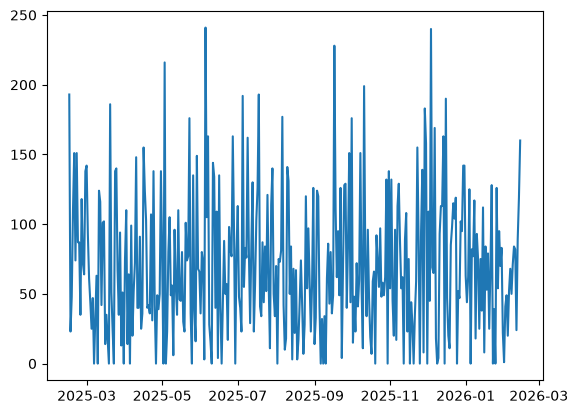

In [38]:
x = df_Quantity['Transaction_Date']
y = df_Quantity['Quantity']
plt.plot(x, y)
plt.show()

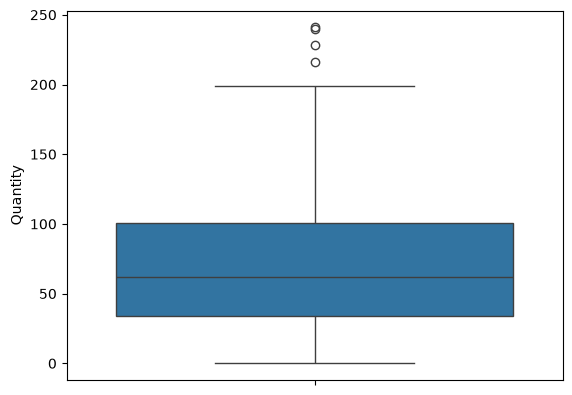

In [39]:
sns.boxplot(y='Quantity', data=df_Quantity)
plt.show()

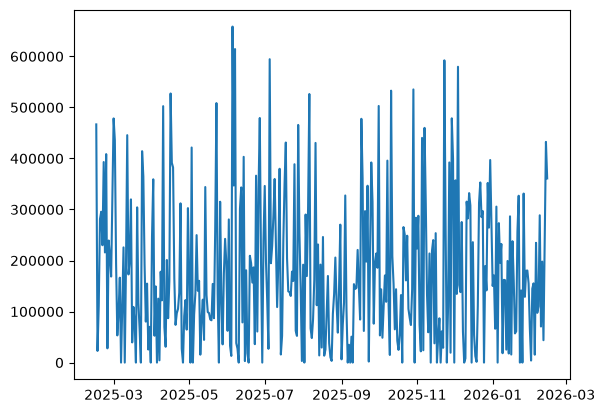

In [40]:
x = df_Sales['Transaction_Date']
y = df_Sales['Total_Amount']
plt.plot(x, y)
plt.show()

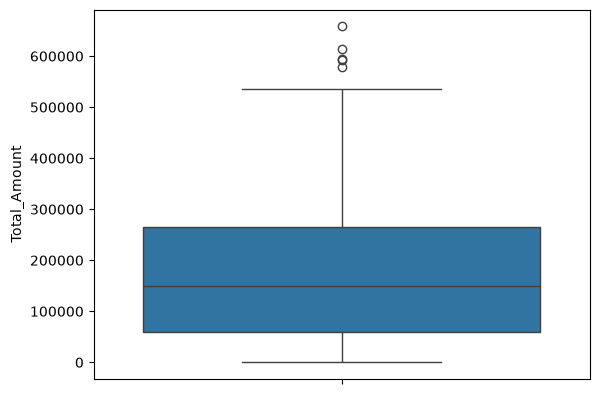

In [41]:
sns.boxplot(y='Total_Amount', data=df_Sales)
plt.show()

In [42]:
df_Quantity['rolling_7'] = df_Quantity['Quantity'].rolling(window=7, center=True).mean()

In [43]:
df_Quantity.head()

,Transaction_Date,Quantity,rolling_7
0,2025-02-15,193,NaN
1,2025-02-16,23,NaN
2,2025-02-17,48,NaN
3,2025-02-18,110,107.142857
4,2025-02-19,151,92.000000


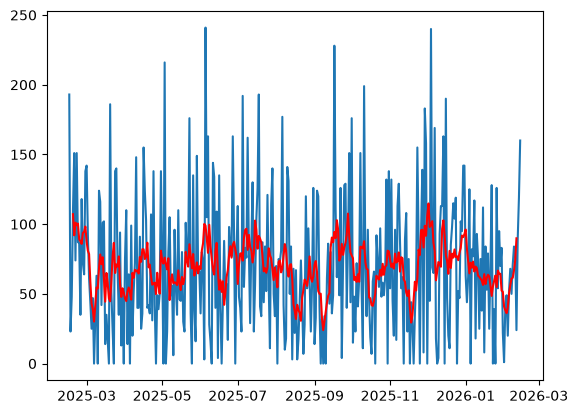

In [44]:
plt.plot(df_Quantity['Transaction_Date'],
         df_Quantity['Quantity'],
         label='Quantity')

plt.plot(df_Quantity['Transaction_Date'],
         df_Quantity['rolling_7'],
         label='Rolling Average',
         color='red')

plt.show()

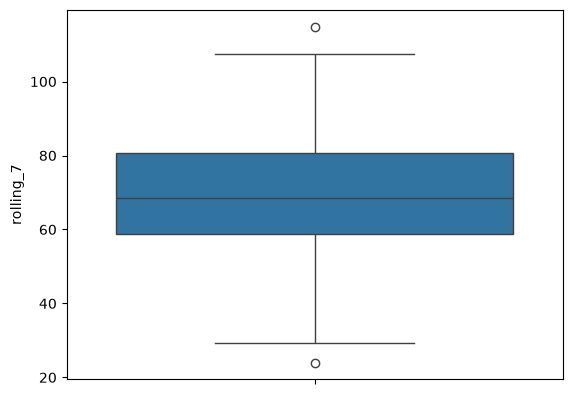

In [45]:
sns.boxplot(y='rolling_7', data=df_Quantity)
plt.show()

In [46]:
df_Quantity.tail(10)

,Transaction_Date,Quantity,rolling_7
355,2026-02-05,52,50.142857
356,2026-02-06,68,56.285714
357,2026-02-07,50,61.000000
358,2026-02-08,71,61.571429
359,2026-02-09,84,66.857143
360,2026-02-10,82,74.142857
361,2026-02-11,24,89.857143
362,2026-02-12,89,NaN
363,2026-02-13,119,NaN
364,2026-02-14,160,NaN


In [47]:
df_Quantity.head(10)

,Transaction_Date,Quantity,rolling_7
0,2025-02-15,193,NaN
1,2025-02-16,23,NaN
2,2025-02-17,48,NaN
3,2025-02-18,110,107.142857
4,2025-02-19,151,92.000000
5,2025-02-20,74,101.142857
6,2025-02-21,151,99.285714
7,2025-02-22,87,100.428571
8,2025-02-23,87,89.142857
9,2025-02-24,35,87.714286


In [48]:
from statsmodels.tsa.seasonal import STL

In [49]:
stl = STL(df_Quantity['Quantity'], period=7)
res = stl.fit()

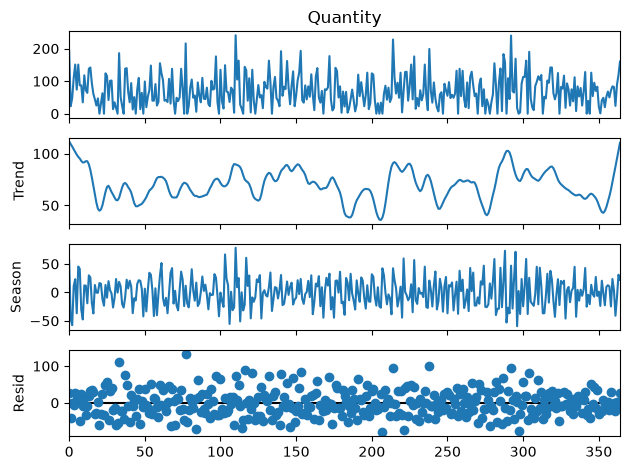

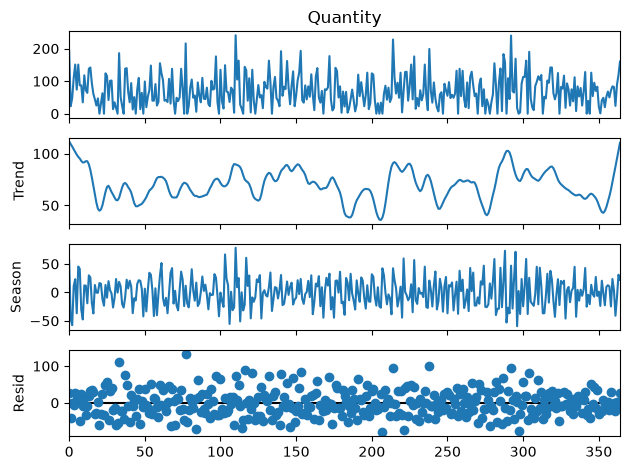

In [50]:
res.plot()

In [51]:
stl = STL(df_Quantity['Quantity'], period=30)
res = stl.fit()

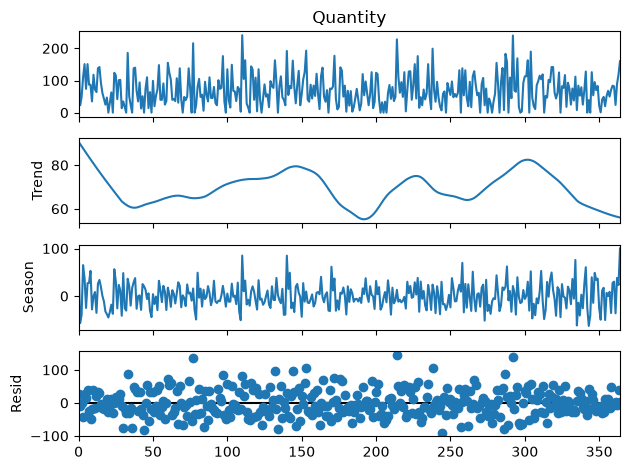

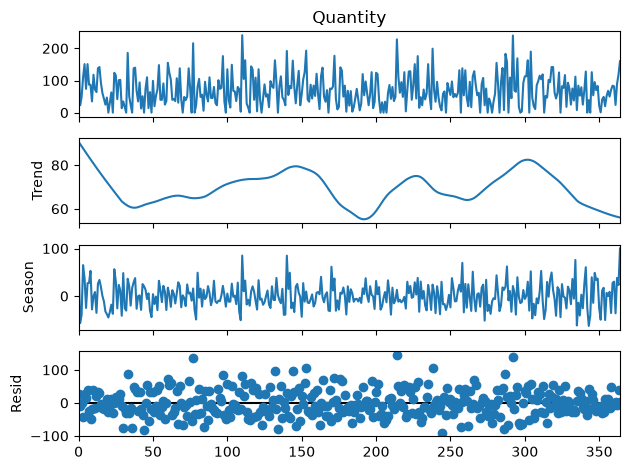

In [52]:
res.plot()

In [53]:
#pip install prophet

In [54]:
Q1 = df_Quantity['Quantity'].quantile(0.25)
Q3 = df_Quantity['Quantity'].quantile(0.75)

IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR

outliers = df_Quantity[df_Quantity['Quantity'] > upper]

In [55]:
outliers

,Transaction_Date,Quantity,rolling_7
77,2025-05-03,216,76.000000
110,2025-06-05,241,99.000000
214,2025-09-17,228,94.428571
292,2025-12-04,240,99.571429


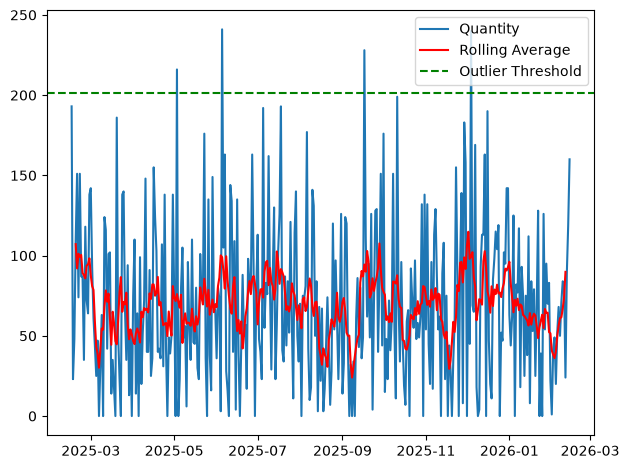

In [56]:
plt.plot(df_Quantity['Transaction_Date'],
         df_Quantity['Quantity'],
         label='Quantity')

plt.plot(df_Quantity['Transaction_Date'],
         df_Quantity['rolling_7'],
         label='Rolling Average',
         color='red')

plt.axhline(y=upper,
            label='Outlier Threshold',
            color='green',
            linestyle='--')

plt.legend()

plt.tight_layout()

plt.show()